# 09 — Jain's Fairness Index (Section 17)

Verifies the standard Jain's Fairness Index formula on known cases, then
computes it over meaningful allocation quantities: task workload,
cumulative energy consumed, and battery stress ((100 - SOC)) per robot,
using output from an actual simulation run (not fabricated numbers).

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))
from fairness import jains_fairness_index, fairness_report

# --- Formula sanity checks ---
print("Equal allocation [5,5,5,5]:", jains_fairness_index([5,5,5,5]), "(expect 1.0)")
print("All-to-one [10,0,0,0]:", jains_fairness_index([10,0,0,0]), "(expect 0.25)")
print("Mixed [3,4,5,2]:", round(jains_fairness_index([3,4,5,2]), 4))


Equal allocation [5,5,5,5]: 1.0 (expect 1.0)
All-to-one [10,0,0,0]: 0.25 (expect 0.25)
Mixed [3,4,5,2]: 0.9074


## Fairness over an actual simulation run

In [2]:
from reallocation import Simulator

sim = Simulator(dataset_root="../data/dataset", run_id="fairness_demo")
result = sim.run(verbose=False)

report = fairness_report(
    robot_ids=list(sim.fleet.robots.keys()),
    completed_counts=sim.completed_counts,
    energy_used=sim.energy_used,
    battery_stress={rid: 100.0 - r.soc for rid, r in sim.fleet.robots.items()},
)
print("Completed tasks per robot:", sim.completed_counts)
print("\nFairness report (this run):")
for k, v in report.items():
    print(f"  {k:26s} {v:.4f}")


Completed tasks per robot: {'UGV01': 2, 'UGV02': 2, 'UGV03': 1, 'UGV04': 1, 'USV01': 3, 'USV02': 1, 'USV03': 1, 'USV04': 2, 'UAV01': 2, 'UAV02': 1, 'UAV03': 2, 'UAV04': 0}

Fairness report (this run):
  workload_fairness          0.7941
  energy_fairness            0.6809
  battery_stress_fairness    0.8774


### Visualizing the two quantities behind the fairness numbers

Jain's index compresses each distribution into one number; the charts
below show the actual per-robot completed-task and energy-consumption
distributions the `workload_fairness` and `energy_fairness` numbers above
were computed from.

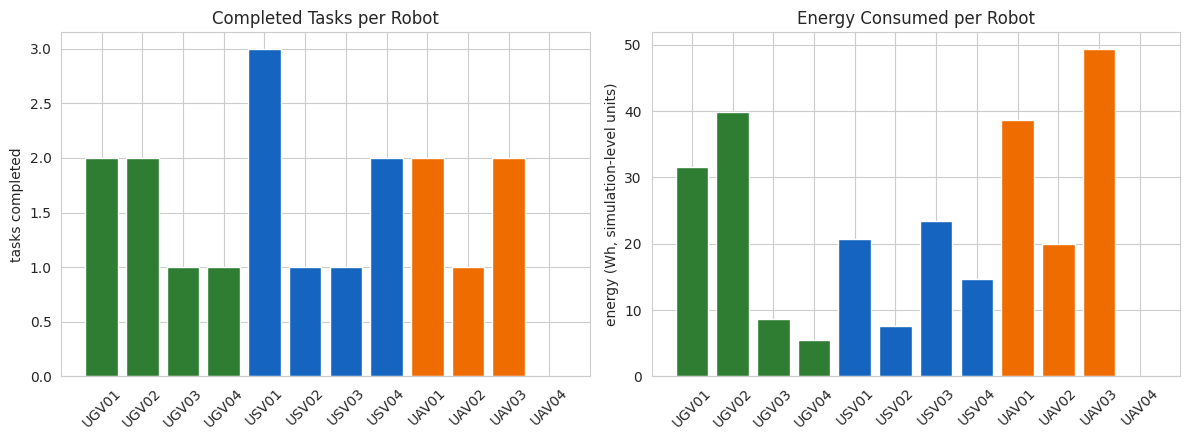

In [3]:
import matplotlib.pyplot as plt
from visualization import plot_workload_and_energy

robot_types = {rid: r.robot_type for rid, r in sim.fleet.robots.items()}
plot_workload_and_energy(sim.completed_counts, sim.energy_used, robot_types,
                          savepath="../results/day3_workload_energy_per_robot.png")
plt.show()


## Interpretation

`workload_fairness` measures how evenly completed tasks are spread across
the 12 robots; `energy_fairness` measures how evenly energy consumption is
spread; `battery_stress_fairness` measures how evenly battery depletion
((100-SOC)) is spread — this is the **battery-aware fairness** metric
requested by the spec. All three use the identical, undistorted Jain
formula over different xi quantities, per Section 17's requirement not to
distort the mathematics.